In [1]:
# ================================
# 1. Imports & Configuration
# ================================

import pandas as pd
import numpy as np

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Reproducibility
np.random.seed(42)

# Parameters
K_LAGS = 6          # 30 minutes of history
DELTA = 6           # 5-minute ahead prediction

TRAIN_DATA_PATH = "train_split_for_ctm.csv"  # adjust if needed
TEST_DATA_PATH = "test_split_for_ctm.csv"

In [2]:
# ================================
# 2. Load Data
# ================================

df = pd.read_csv(TRAIN_DATA_PATH)
df_test = pd.read_csv(TEST_DATA_PATH)

#convert from mph to kmh

df["speed"] = df["speed"] * 1.6
df_test["speed"] = df_test["speed"] * 1.6

print("df Shape:", df.shape)
df.head()

print("df_test shape:", df_test.shape)
df_test.head()

df Shape: (11495, 4)
df_test shape: (4243, 4)


,Station,datetime,flow,speed
0,717486,6/20/2005 0:00,3060,125.60
1,717486,6/20/2005 0:05,2760,123.68
2,717486,6/20/2005 0:10,2664,128.32
3,717486,6/20/2005 0:15,2652,125.44
4,717486,6/20/2005 0:20,1596,112.16


In [3]:
# ================================
# 3. Preprocessing
# ================================

# Keep only relevant columns
df = df[['Station', 'datetime', 'flow', 'speed']]
df_test = df_test[['Station', 'datetime', 'flow', 'speed']]

# Drop rows where flow or speed is missing
df = df.dropna(subset=["flow", "speed"]).reset_index(drop=True)
df_test = df_test.dropna(subset=["flow", "speed"]).reset_index(drop=True)

print("df shape after dropping raw NaNs:", df.shape)

df.head()

print("df_test shape after dropping raw NaNs:", df_test.shape)

df_test.head()

df shape after dropping raw NaNs: (11495, 4)
df_test shape after dropping raw NaNs: (4243, 4)


,Station,datetime,flow,speed
0,717486,6/20/2005 0:00,3060,125.60
1,717486,6/20/2005 0:05,2760,123.68
2,717486,6/20/2005 0:10,2664,128.32
3,717486,6/20/2005 0:15,2652,125.44
4,717486,6/20/2005 0:20,1596,112.16


In [4]:
# ================================
# 4. Construct Spatiotemporal Features
# ================================

df["datetime"] = pd.to_datetime(df["datetime"])
df_test["datetime"] = pd.to_datetime(df_test["datetime"])

# Preserve station order AS IT APPEARS IN THE TRAIN FILE
station_order = list(pd.unique(df["Station"]))

# Optional safety check
missing_in_test = set(station_order) - set(df_test["Station"].unique())
extra_in_test = set(df_test["Station"].unique()) - set(station_order)

print("Train station order:", station_order)
print("Missing in test:", missing_in_test)
print("Extra in test:", extra_in_test)

# Restrict to common stations only if needed
common_stations = [s for s in station_order if s in set(df_test["Station"].unique())]
df = df[df["Station"].isin(common_stations)].copy()
df_test = df_test[df_test["Station"].isin(common_stations)].copy()

station_order = common_stations
print("Using station order:", station_order)


def build_spatiotemporal_features(df_in, station_order, k_lags, delta):
    df_local = df_in.copy()
    df_local["datetime"] = pd.to_datetime(df_local["datetime"])

    # Keep original row order within each station, but make sure pivot columns follow station_order
    flow_pivot = (
        df_local.pivot(index="datetime", columns="Station", values="flow")
        .reindex(columns=station_order)
        .sort_index()
    )

    speed_pivot = (
        df_local.pivot(index="datetime", columns="Station", values="speed")
        .reindex(columns=station_order)
        .sort_index()
    )

    feature_frames = []

    for lag in range(k_lags):
        flow_lag = flow_pivot.shift(lag).copy()
        speed_lag = speed_pivot.shift(lag).copy()

        flow_lag.columns = [f"flow_s{station}_lag{lag}" for station in flow_lag.columns]
        speed_lag.columns = [f"speed_s{station}_lag{lag}" for station in speed_lag.columns]

        feature_frames.append(flow_lag)
        feature_frames.append(speed_lag)

    X = pd.concat(feature_frames, axis=1)

    y_flow = flow_pivot.shift(-delta).copy()
    y_speed = speed_pivot.shift(-delta).copy()

    y_flow.columns = [f"flow_target_s{station}" for station in y_flow.columns]
    y_speed.columns = [f"speed_target_s{station}" for station in y_speed.columns]

    full_df = pd.concat([X, y_flow, y_speed], axis=1).dropna()

    X = full_df[X.columns]
    y_flow = full_df[y_flow.columns]
    y_speed = full_df[y_speed.columns]

    return X, y_flow, y_speed


X_train, y_flow_train, y_speed_train = build_spatiotemporal_features(
    df, station_order, K_LAGS, DELTA
)

X_test, y_flow_test, y_speed_test = build_spatiotemporal_features(
    df_test, station_order, K_LAGS, DELTA
)

print("Train X shape:", X_train.shape)
print("Test X shape:", X_test.shape)
print("Train y_flow shape:", y_flow_train.shape)
print("Test y_flow shape:", y_flow_test.shape)
print("Train y_speed shape:", y_speed_train.shape)
print("Test y_speed shape:", y_speed_test.shape)

Train station order: [np.int64(717486), np.int64(764766), np.int64(717488), np.int64(717489), np.int64(717490)]
Missing in test: set()
Extra in test: set()
Using station order: [np.int64(717486), np.int64(764766), np.int64(717488), np.int64(717489), np.int64(717490)]
Train X shape: (2288, 60)
Test X shape: (837, 60)
Train y_flow shape: (2288, 5)
Test y_flow shape: (837, 5)
Train y_speed shape: (2288, 5)
Test y_speed shape: (837, 5)


In [5]:
# ================================
# 5. Verify Feature Alignment
# ================================

assert list(X_train.columns) == list(X_test.columns), "Feature mismatch between train and test!"
assert list(y_flow_train.columns) == list(y_flow_test.columns), "Flow target mismatch!"
assert list(y_speed_train.columns) == list(y_speed_test.columns), "Speed target mismatch!"

print("Feature alignment OK")
print("Number of feature columns:", len(X_train.columns))
print("Number of stations in targets:", y_flow_train.shape[1])

Feature alignment OK
Number of feature columns: 60
Number of stations in targets: 5


In [6]:
# ================================
# 6. Create Day Index
# ================================

train_dates = sorted(pd.Series(X_train.index.date).unique())
test_dates = sorted(pd.Series(X_test.index.date).unique())

print("Unique dates train:")
for i, d in enumerate(train_dates, start=1):
    print(i, d)
print("Total unique train dates:", len(train_dates))

print("\nUnique dates test:")
for i, d in enumerate(test_dates, start=1):
    print(i, d)
print("Total unique test dates:", len(test_dates))

Unique dates train:
1 2005-06-08
2 2005-06-09
3 2005-06-10
4 2005-06-13
5 2005-06-14
6 2005-06-15
7 2005-06-16
8 2005-06-17
Total unique train dates: 8

Unique dates test:
1 2005-06-20
2 2005-06-21
3 2005-06-22
Total unique test dates: 3


In [7]:
# ================================
# 7A. Train / Test Split
# ================================

# Already defined by separate files
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (2288, 60)
Test shape: (837, 60)


In [8]:
# ================================
# 8. Feature Scaling
# ================================

continuous_cols = list(X_train.columns)
print("Continuous features:", len(continuous_cols))

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train[continuous_cols]),
    columns=continuous_cols,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test[continuous_cols]),
    columns=continuous_cols,
    index=X_test.index
)

print("Scaled train shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Continuous features: 60
Scaled train shape: (2288, 60)
Scaled test shape: (837, 60)


In [9]:
ctm_train = pd.read_csv("ctm_outputs__train_forResiduals.csv")
ctm_test = pd.read_csv("ctm_outputs_test_D6_forResiduals.csv")

ctm_train["datetime"] = pd.to_datetime(ctm_train["datetime"])
ctm_test["datetime"] = pd.to_datetime(ctm_test["datetime"])

print(ctm_train.shape)
print(ctm_test.shape)

(2290, 21)
(834, 21)


In [10]:
# Match the target column names already used in your notebook
ctm_flow_train = ctm_train[[
    "flow_CTM_717486",
    "flow_CTM_764766",
    "flow_CTM_717488",
    "flow_CTM_717489",
    "flow_CTM_717490"
]].copy()

ctm_flow_test = ctm_test[[
    "flow_CTM_717486",
    "flow_CTM_764766",
    "flow_CTM_717488",
    "flow_CTM_717489",
    "flow_CTM_717490"
]].copy()

ctm_speed_train = ctm_train[[
    "speed_CTM_717486",
    "speed_CTM_764766",
    "speed_CTM_717488",
    "speed_CTM_717489",
    "speed_CTM_717490"
]].copy()

ctm_speed_test = ctm_test[[
    "speed_CTM_717486",
    "speed_CTM_764766",
    "speed_CTM_717488",
    "speed_CTM_717489",
    "speed_CTM_717490"
]].copy()

ctm_flow_train.columns = y_flow_train.columns
ctm_flow_test.columns = y_flow_test.columns
ctm_speed_train.columns = y_speed_train.columns
ctm_speed_test.columns = y_speed_test.columns

ctm_flow_train.index = pd.to_datetime(ctm_train["datetime"])
ctm_flow_test.index = pd.to_datetime(ctm_test["datetime"])
ctm_speed_train.index = pd.to_datetime(ctm_train["datetime"])
ctm_speed_test.index = pd.to_datetime(ctm_test["datetime"])

In [11]:
# Align train on common timestamps
common_train_idx = y_flow_train.index.intersection(ctm_flow_train.index)

X_train_hybrid = X_train_scaled.loc[common_train_idx]
y_flow_train_hybrid = y_flow_train.loc[common_train_idx]
y_speed_train_hybrid = y_speed_train.loc[common_train_idx]

ctm_flow_train_hybrid = ctm_flow_train.loc[common_train_idx]
ctm_speed_train_hybrid = ctm_speed_train.loc[common_train_idx]

# Align test on common timestamps
common_test_idx = y_flow_test.index.intersection(ctm_flow_test.index)

X_test_hybrid = X_test_scaled.loc[common_test_idx]
y_flow_test_hybrid = y_flow_test.loc[common_test_idx]
y_speed_test_hybrid = y_speed_test.loc[common_test_idx]

ctm_flow_test_hybrid = ctm_flow_test.loc[common_test_idx]
ctm_speed_test_hybrid = ctm_speed_test.loc[common_test_idx]

print("Common train rows:", len(common_train_idx))
print("Common test rows:", len(common_test_idx))

print("X_train_hybrid:", X_train_hybrid.shape)
print("y_flow_train_hybrid:", y_flow_train_hybrid.shape)
print("ctm_flow_train_hybrid:", ctm_flow_train_hybrid.shape)

print("X_test_hybrid:", X_test_hybrid.shape)
print("y_flow_test_hybrid:", y_flow_test_hybrid.shape)
print("ctm_flow_test_hybrid:", ctm_flow_test_hybrid.shape)

Common train rows: 2284
Common test rows: 833
X_train_hybrid: (2284, 60)
y_flow_train_hybrid: (2284, 5)
ctm_flow_train_hybrid: (2284, 5)
X_test_hybrid: (833, 60)
y_flow_test_hybrid: (833, 5)
ctm_flow_test_hybrid: (833, 5)


In [12]:
flow_resid_train = y_flow_train_hybrid - ctm_flow_train_hybrid
flow_resid_test = y_flow_test_hybrid - ctm_flow_test_hybrid

speed_resid_train = y_speed_train_hybrid - ctm_speed_train_hybrid
speed_resid_test = y_speed_test_hybrid - ctm_speed_test_hybrid

In [13]:
# ================================
# 9. Prepare Training Metadata for CV
# ================================

train_meta = pd.DataFrame(index=X_train_scaled.index)
train_meta["date_only"] = train_meta.index.date

print("train_meta shape:", train_meta.shape)
train_meta.head()

train_meta shape: (2288, 1)


,date_only
datetime,
2005-06-08 00:50:00,2005-06-08
2005-06-08 00:55:00,2005-06-08
2005-06-08 01:00:00,2005-06-08
2005-06-08 01:05:00,2005-06-08
2005-06-08 01:10:00,2005-06-08


In [14]:
# ================================
# 10. Rolling CV Function
# ================================

def evaluate_lambda(lambda_value, X_scaled, y, date_index, folds):
    rmses = []

    for fold_train_dates, fold_val_dates in folds:
        train_mask = pd.Series(date_index).isin(fold_train_dates).values
        val_mask = pd.Series(date_index).isin(fold_val_dates).values

        X_fold_train = X_scaled.iloc[train_mask]
        y_fold_train = y.iloc[train_mask]

        X_fold_val = X_scaled.iloc[val_mask]
        y_fold_val = y.iloc[val_mask]

        model = Ridge(alpha=lambda_value)
        model.fit(X_fold_train, y_fold_train)

        preds = model.predict(X_fold_val)
        rmse = np.sqrt(mean_squared_error(y_fold_val, preds))
        rmses.append(rmse)

    return np.mean(rmses)

In [15]:
# ================================
# Rebuild Rolling CV Folds
# ================================

folds = []

# Example rolling folds:
# Fold 1: first 4 train days -> day 5 val
# Fold 2: first 5 train days -> day 6 val
# Fold 3: first 6 train days -> day 7 val
# Fold 4: first 7 train days -> day 8 val

for i in range(4, len(train_dates)):
    fold_train_dates = train_dates[:i]
    fold_val_dates = [train_dates[i]]
    folds.append((fold_train_dates, fold_val_dates))

print("Folds created:", len(folds))
for idx, (tr, val) in enumerate(folds, start=1):
    print(f"Fold {idx}: Train {tr} | Val {val}")

Folds created: 4
Fold 1: Train [datetime.date(2005, 6, 8), datetime.date(2005, 6, 9), datetime.date(2005, 6, 10), datetime.date(2005, 6, 13)] | Val [datetime.date(2005, 6, 14)]
Fold 2: Train [datetime.date(2005, 6, 8), datetime.date(2005, 6, 9), datetime.date(2005, 6, 10), datetime.date(2005, 6, 13), datetime.date(2005, 6, 14)] | Val [datetime.date(2005, 6, 15)]
Fold 3: Train [datetime.date(2005, 6, 8), datetime.date(2005, 6, 9), datetime.date(2005, 6, 10), datetime.date(2005, 6, 13), datetime.date(2005, 6, 14), datetime.date(2005, 6, 15)] | Val [datetime.date(2005, 6, 16)]
Fold 4: Train [datetime.date(2005, 6, 8), datetime.date(2005, 6, 9), datetime.date(2005, 6, 10), datetime.date(2005, 6, 13), datetime.date(2005, 6, 14), datetime.date(2005, 6, 15), datetime.date(2005, 6, 16)] | Val [datetime.date(2005, 6, 17)]


In [16]:
lambda_grid = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]
train_date_index_hybrid = X_train_hybrid.index.date

hybrid_flow_results = {}
for lam in lambda_grid:
    rmse = evaluate_lambda(
        lambda_value=lam,
        X_scaled=X_train_hybrid,
        y=flow_resid_train,
        date_index=train_date_index_hybrid,
        folds=folds
    )
    hybrid_flow_results[lam] = rmse
    print(f"Flow residual lambda {lam}: RMSE = {rmse:.3f}")

best_lambda_hybrid_flow = min(hybrid_flow_results, key=hybrid_flow_results.get)
print("Best hybrid flow lambda:", best_lambda_hybrid_flow)

hybrid_speed_results = {}
for lam in lambda_grid:
    rmse = evaluate_lambda(
        lambda_value=lam,
        X_scaled=X_train_hybrid,
        y=speed_resid_train,
        date_index=train_date_index_hybrid,
        folds=folds
    )
    hybrid_speed_results[lam] = rmse
    print(f"Speed residual lambda {lam}: RMSE = {rmse:.3f}")

best_lambda_hybrid_speed = min(hybrid_speed_results, key=hybrid_speed_results.get)
print("Best hybrid speed lambda:", best_lambda_hybrid_speed)

Flow residual lambda 0.0001: RMSE = 1583.719
Flow residual lambda 0.001: RMSE = 1582.735
Flow residual lambda 0.01: RMSE = 1574.476
Flow residual lambda 0.1: RMSE = 1535.667
Flow residual lambda 1: RMSE = 1433.316
Flow residual lambda 10: RMSE = 1350.600
Flow residual lambda 100: RMSE = 1313.283
Best hybrid flow lambda: 100
Speed residual lambda 0.0001: RMSE = 14.889
Speed residual lambda 0.001: RMSE = 14.887
Speed residual lambda 0.01: RMSE = 14.867
Speed residual lambda 0.1: RMSE = 14.771
Speed residual lambda 1: RMSE = 14.461
Speed residual lambda 10: RMSE = 13.953
Speed residual lambda 100: RMSE = 13.751
Best hybrid speed lambda: 100


In [17]:
# ================================
# Train Hybrid Residual Models
# ================================
hybrid_flow_model = Ridge(alpha=best_lambda_hybrid_flow)
hybrid_flow_model.fit(X_train_hybrid, flow_resid_train)

hybrid_speed_model = Ridge(alpha=best_lambda_hybrid_speed)
hybrid_speed_model.fit(X_train_hybrid, speed_resid_train)

,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",100
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",None


In [18]:
flow_resid_preds = pd.DataFrame(
    hybrid_flow_model.predict(X_test_hybrid),
    columns=flow_resid_test.columns,
    index=X_test_hybrid.index
)

speed_resid_preds = pd.DataFrame(
    hybrid_speed_model.predict(X_test_hybrid),
    columns=speed_resid_test.columns,
    index=X_test_hybrid.index
)

hybrid_flow_preds = ctm_flow_test_hybrid + flow_resid_preds
hybrid_speed_preds = ctm_speed_test_hybrid + speed_resid_preds

In [19]:
hybrid_results = []

for station in station_order:
    flow_col = f"flow_target_s{station}"
    speed_col = f"speed_target_s{station}"

    flow_rmse = np.sqrt(mean_squared_error(
        y_flow_test_hybrid[flow_col],
        hybrid_flow_preds[flow_col]
    ))

    speed_rmse = np.sqrt(mean_squared_error(
        y_speed_test_hybrid[speed_col],
        hybrid_speed_preds[speed_col]
    ))

    hybrid_results.append((station, flow_rmse, speed_rmse))

hybrid_results_df = pd.DataFrame(
    hybrid_results,
    columns=["Station", "Hybrid_Flow_RMSE", "Hybrid_Speed_RMSE"]
)

print(hybrid_results_df)
print("\nAverage Hybrid Flow RMSE:", hybrid_results_df["Hybrid_Flow_RMSE"].mean())
print("Average Hybrid Speed RMSE:", hybrid_results_df["Hybrid_Speed_RMSE"].mean())

   Station  Hybrid_Flow_RMSE  Hybrid_Speed_RMSE
0   717486        638.804002           4.970904
1   764766        616.368895           4.119393
2   717488        526.724812           7.070051
3   717489       1183.264514          18.010228
4   717490       1032.336609          15.303392

Average Hybrid Flow RMSE: 799.499766499411
Average Hybrid Speed RMSE: 9.894793864536926


In [20]:
# ================================
# 11. Tune Lambda for Flow
# ================================

lambda_grid = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]
flow_results = {}

train_date_index = X_train_scaled.index.date

for lam in lambda_grid:
    rmse = evaluate_lambda(
        lambda_value=lam,
        X_scaled=X_train_scaled,
        y=y_flow_train,
        date_index=train_date_index,
        folds=folds
    )
    flow_results[lam] = rmse
    print(f"Lambda {lam}: RMSE = {rmse:.3f}")

best_lambda_flow = min(flow_results, key=flow_results.get)
print("\nBest lambda (flow):", best_lambda_flow)

Lambda 0.0001: RMSE = 1581.106
Lambda 0.001: RMSE = 1580.031
Lambda 0.01: RMSE = 1570.919
Lambda 0.1: RMSE = 1525.767
Lambda 1: RMSE = 1394.192
Lambda 10: RMSE = 1263.281
Lambda 100: RMSE = 1191.666

Best lambda (flow): 100


In [21]:
# ================================
# 12. Tune Lambda for Speed
# ================================

speed_results = {}

for lam in lambda_grid:
    rmse = evaluate_lambda(
        lambda_value=lam,
        X_scaled=X_train_scaled,
        y=y_speed_train,
        date_index=train_date_index,
        folds=folds
    )
    speed_results[lam] = rmse
    print(f"Lambda {lam}: RMSE = {rmse:.3f}")

best_lambda_speed = min(speed_results, key=speed_results.get)
print("\nBest lambda (speed):", best_lambda_speed)

Lambda 0.0001: RMSE = 14.784
Lambda 0.001: RMSE = 14.782
Lambda 0.01: RMSE = 14.762
Lambda 0.1: RMSE = 14.666
Lambda 1: RMSE = 14.359
Lambda 10: RMSE = 13.875
Lambda 100: RMSE = 13.630

Best lambda (speed): 100


In [22]:
# ================================
# 13. Train Final Models
# ================================

flow_model = Ridge(alpha=best_lambda_flow)
flow_model.fit(X_train_scaled, y_flow_train)

speed_model = Ridge(alpha=best_lambda_speed)
speed_model.fit(X_train_scaled, y_speed_train)

,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",100
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",None


In [23]:
# ================================
# 14. Predict on Test Set
# ================================

flow_preds = pd.DataFrame(
    flow_model.predict(X_test_scaled),
    columns=y_flow_test.columns,
    index=X_test_scaled.index
)

speed_preds = pd.DataFrame(
    speed_model.predict(X_test_scaled),
    columns=y_speed_test.columns,
    index=X_test_scaled.index
)

print(flow_preds.shape, speed_preds.shape)

(837, 5) (837, 5)


In [24]:
# ================================
# 15. Per-Station RMSE
# ================================

station_results = []

for station in station_order:
    flow_col = f"flow_target_s{station}"
    speed_col = f"speed_target_s{station}"

    flow_rmse = np.sqrt(mean_squared_error(y_flow_test[flow_col], flow_preds[flow_col]))
    speed_rmse = np.sqrt(mean_squared_error(y_speed_test[speed_col], speed_preds[speed_col]))

    station_results.append((station, flow_rmse, speed_rmse))

results_df = pd.DataFrame(
    station_results,
    columns=["Station", "Flow_RMSE", "Speed_RMSE"]
)

print(results_df)
print("\nAverage Flow RMSE:", results_df["Flow_RMSE"].mean())
print("Average Speed RMSE:", results_df["Speed_RMSE"].mean())

   Station    Flow_RMSE  Speed_RMSE
0   717486   591.747590    3.742564
1   764766   597.819535    2.859709
2   717488   576.213605    3.259036
3   717489  1243.470903   15.966028
4   717490  1085.307558   15.113973

Average Flow RMSE: 818.9118382986668
Average Speed RMSE: 8.188262027173726


In [25]:
# ================================
# 16. Persistence Baseline
# ================================

persist_results = []

for station in station_order:
    flow_target_col = f"flow_target_s{station}"
    speed_target_col = f"speed_target_s{station}"

    flow_persist_col = f"flow_s{station}_lag0"
    speed_persist_col = f"speed_s{station}_lag0"

    flow_rmse = np.sqrt(mean_squared_error(y_flow_test[flow_target_col], X_test[flow_persist_col]))
    speed_rmse = np.sqrt(mean_squared_error(y_speed_test[speed_target_col], X_test[speed_persist_col]))

    persist_results.append((station, flow_rmse, speed_rmse))

persist_df = pd.DataFrame(
    persist_results,
    columns=["Station", "Flow_RMSE_Persist", "Speed_RMSE_Persist"]
)

print(persist_df)
print("\nAverage Flow RMSE (Persist):", persist_df["Flow_RMSE_Persist"].mean())
print("Average Speed RMSE (Persist):", persist_df["Speed_RMSE_Persist"].mean())

   Station  Flow_RMSE_Persist  Speed_RMSE_Persist
0   717486         585.970457            2.651086
1   764766         622.722983            2.554097
2   717488         582.291506            2.542647
3   717489        1389.814067           18.559623
4   717490        1220.755698           17.663154

Average Flow RMSE (Persist): 880.3109420623539
Average Speed RMSE (Persist): 8.794121382004798


In [26]:
comparison_df = results_df.copy()
comparison_df = comparison_df.merge(persist_df, on="Station")
comparison_df = comparison_df.merge(hybrid_results_df, on="Station")

print(comparison_df)

print("\nAverages:")
print("Ridge flow:", comparison_df["Flow_RMSE"].mean())
print("Persistence flow:", comparison_df["Flow_RMSE_Persist"].mean())
print("Hybrid flow:", comparison_df["Hybrid_Flow_RMSE"].mean())

print("Ridge speed:", comparison_df["Speed_RMSE"].mean())
print("Persistence speed:", comparison_df["Speed_RMSE_Persist"].mean())
print("Hybrid speed:", comparison_df["Hybrid_Speed_RMSE"].mean())

   Station    Flow_RMSE  Speed_RMSE  Flow_RMSE_Persist  Speed_RMSE_Persist  \
0   717486   591.747590    3.742564         585.970457            2.651086   
1   764766   597.819535    2.859709         622.722983            2.554097   
2   717488   576.213605    3.259036         582.291506            2.542647   
3   717489  1243.470903   15.966028        1389.814067           18.559623   
4   717490  1085.307558   15.113973        1220.755698           17.663154   

   Hybrid_Flow_RMSE  Hybrid_Speed_RMSE  
0        638.804002           4.970904  
1        616.368895           4.119393  
2        526.724812           7.070051  
3       1183.264514          18.010228  
4       1032.336609          15.303392  

Averages:
Ridge flow: 818.9118382986668
Persistence flow: 880.3109420623539
Hybrid flow: 799.499766499411
Ridge speed: 8.188262027173726
Persistence speed: 8.794121382004798
Hybrid speed: 9.894793864536926


In [27]:
feature_cols = list(X_train_scaled.columns)
print("Total feature columns:", len(feature_cols))

Total feature columns: 60


In [28]:
# ================================
# Select One Test Day for Plotting
# ================================

plot_day = test_dates[0]
plot_mask = pd.Series(X_test_scaled.index.date, index=X_test_scaled.index) == plot_day

plot_times = X_test_scaled.index[plot_mask]
print("Plotting date:", plot_day)

Plotting date: 2005-06-20


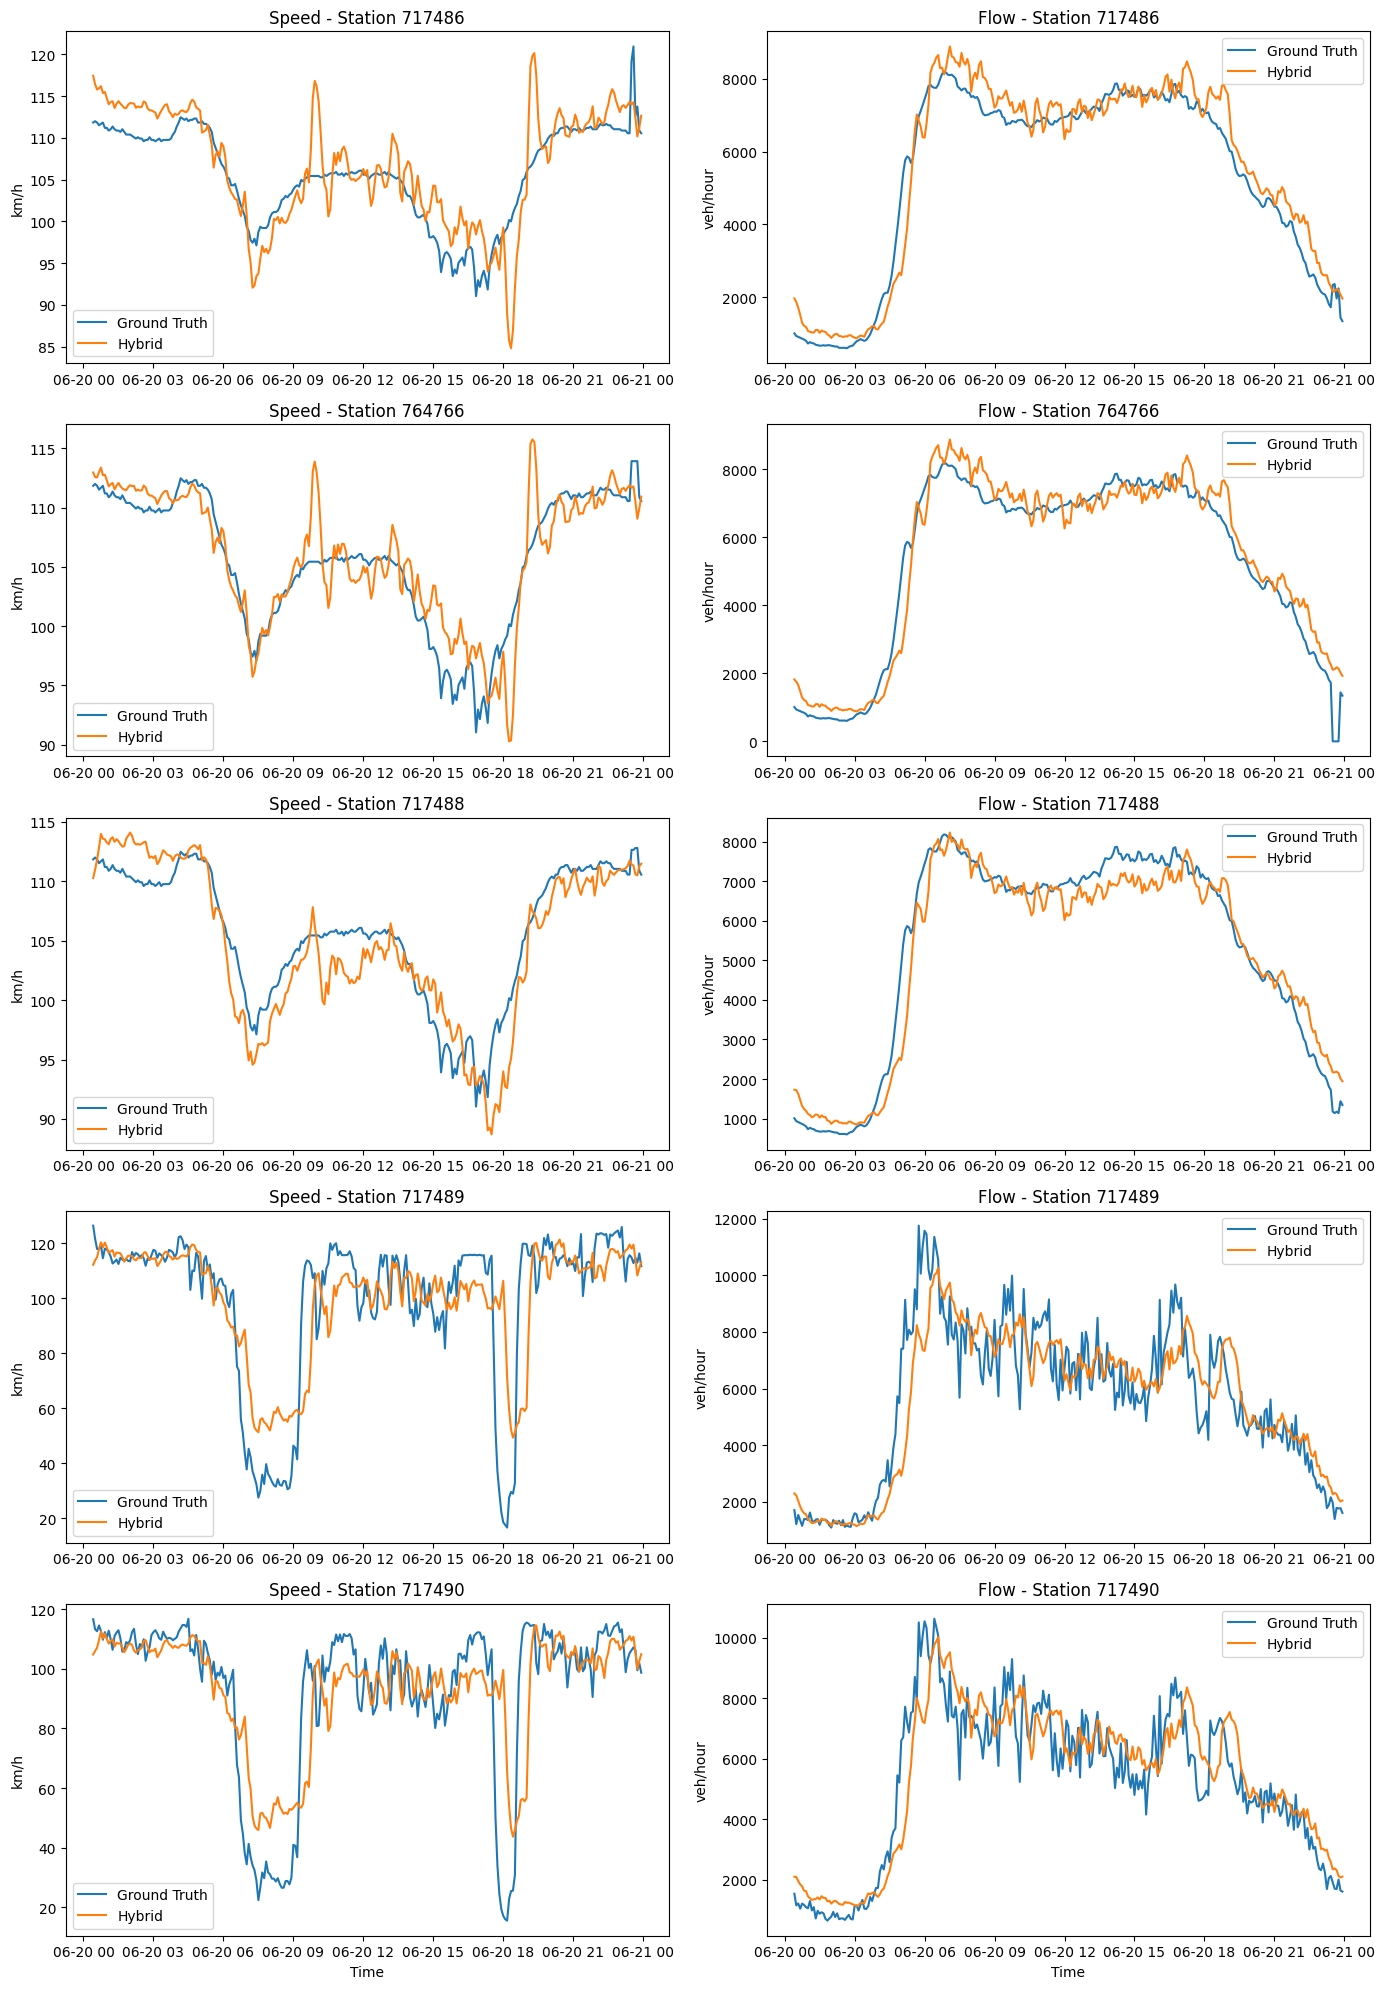

In [29]:
# ================================
# Multi-Station Prediction Plot
# ================================

fig, axes = plt.subplots(len(station_order), 2, figsize=(14, 4 * len(station_order)))

if len(station_order) == 1:
    axes = np.array([axes])

for i, station in enumerate(station_order):
    flow_col = f"flow_target_s{station}"
    speed_col = f"speed_target_s{station}"

    # Speed
    axes[i, 0].plot(plot_times, y_speed_test.loc[plot_times, speed_col])
    axes[i, 0].plot(plot_times, speed_preds.loc[plot_times, speed_col])
    axes[i, 0].set_title(f"Speed - Station {station}")
    axes[i, 0].set_ylabel("km/h")
    axes[i, 0].legend(["Ground Truth", "Hybrid"])

    # Flow
    axes[i, 1].plot(plot_times, y_flow_test.loc[plot_times, flow_col])
    axes[i, 1].plot(plot_times, flow_preds.loc[plot_times, flow_col])
    axes[i, 1].set_title(f"Flow - Station {station}")
    axes[i, 1].set_ylabel("veh/hour")
    axes[i, 1].legend(["Ground Truth", "Hybrid"])

axes[-1, 0].set_xlabel("Time")
axes[-1, 1].set_xlabel("Time")
plt.tight_layout()
plt.show()

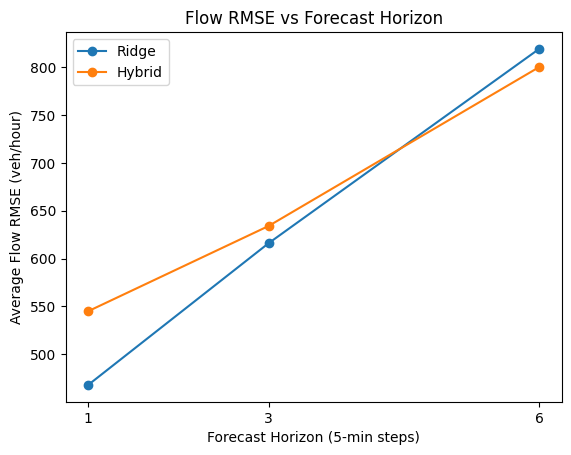

In [30]:
# ================================
# Flow RMSE vs Horizon
# ================================

horizons = [1, 3, 6]

ridge_flow = [468, 616, 819]
hybrid_flow = [545, 634, 800]

plt.figure()
plt.plot(horizons, ridge_flow, marker='o')
plt.plot(horizons, hybrid_flow, marker='o')

plt.xlabel("Forecast Horizon (5-min steps)")
plt.ylabel("Average Flow RMSE (veh/hour)")
plt.title("Flow RMSE vs Forecast Horizon")

plt.xticks(horizons)
plt.legend(["Ridge", "Hybrid"])

plt.show()

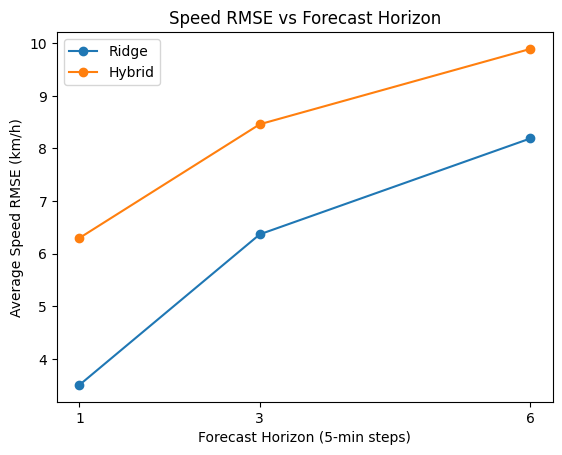

In [31]:
# ================================
# Speed RMSE vs Horizon
# ================================

ridge_speed = [3.51, 6.37, 8.19]
hybrid_speed = [6.3, 8.46, 9.89]

plt.figure()
plt.plot(horizons, ridge_speed, marker='o')
plt.plot(horizons, hybrid_speed, marker='o')

plt.xlabel("Forecast Horizon (5-min steps)")
plt.ylabel("Average Speed RMSE (km/h)")
plt.title("Speed RMSE vs Forecast Horizon")

plt.xticks(horizons)
plt.legend(["Ridge", "Hybrid"])

plt.show()

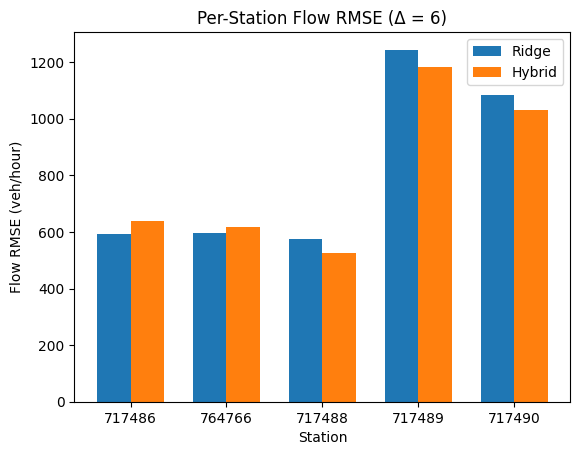

In [32]:
# ================================
# Per-Station Flow RMSE (Δ=6)
# ================================

stations = ["717486", "764766", "717488", "717489", "717490"]

ridge_flow_6 = [592, 598, 576, 1244, 1085]
hybrid_flow_6 = [639, 616, 527, 1183, 1032]

x = np.arange(len(stations))
width = 0.35

plt.figure()
plt.bar(x - width/2, ridge_flow_6, width)
plt.bar(x + width/2, hybrid_flow_6, width)

plt.xticks(x, stations)
plt.xlabel("Station")
plt.ylabel("Flow RMSE (veh/hour)")
plt.title("Per-Station Flow RMSE (Δ = 6)")
plt.legend(["Ridge", "Hybrid"])

plt.show()

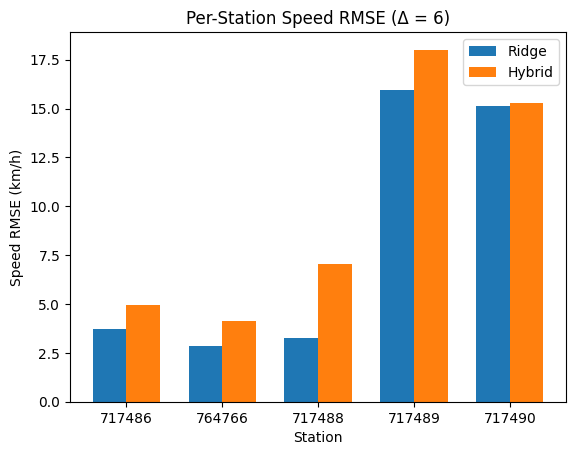

In [33]:
# ================================
# Per-Station Speed RMSE (Δ=6)
# ================================

ridge_speed_6 = [3.74, 2.86, 3.26, 15.97, 15.11]
hybrid_speed_6 = [4.97, 4.12, 7.07, 18.01, 15.3]

plt.figure()
plt.bar(x - width/2, ridge_speed_6, width)
plt.bar(x + width/2, hybrid_speed_6, width)

plt.xticks(x, stations)
plt.xlabel("Station")
plt.ylabel("Speed RMSE (km/h)")
plt.title("Per-Station Speed RMSE (Δ = 6)")
plt.legend(["Ridge", "Hybrid"])

plt.show()